In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor

# Updated to raw GitHub URL to avoid parsing the HTML webpage
url = "https://raw.githubusercontent.com/tusharvargude/employee-attrition-prediction/main/hr_attrition.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


0 missing values
Attrition
No     0.838776
Yes    0.161224
Name: proportion, dtype: float64


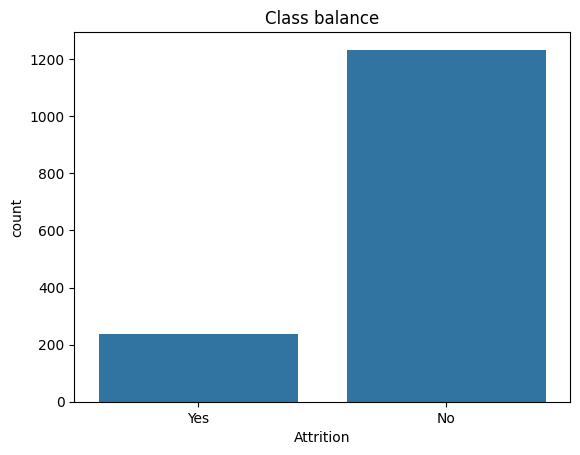

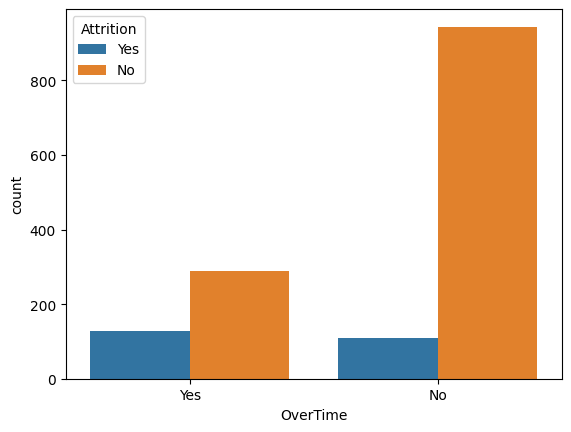

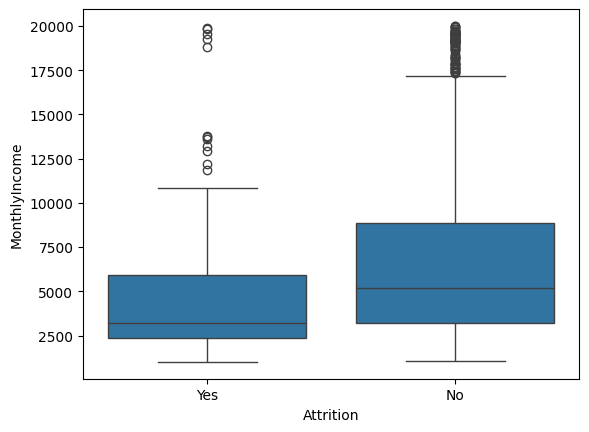

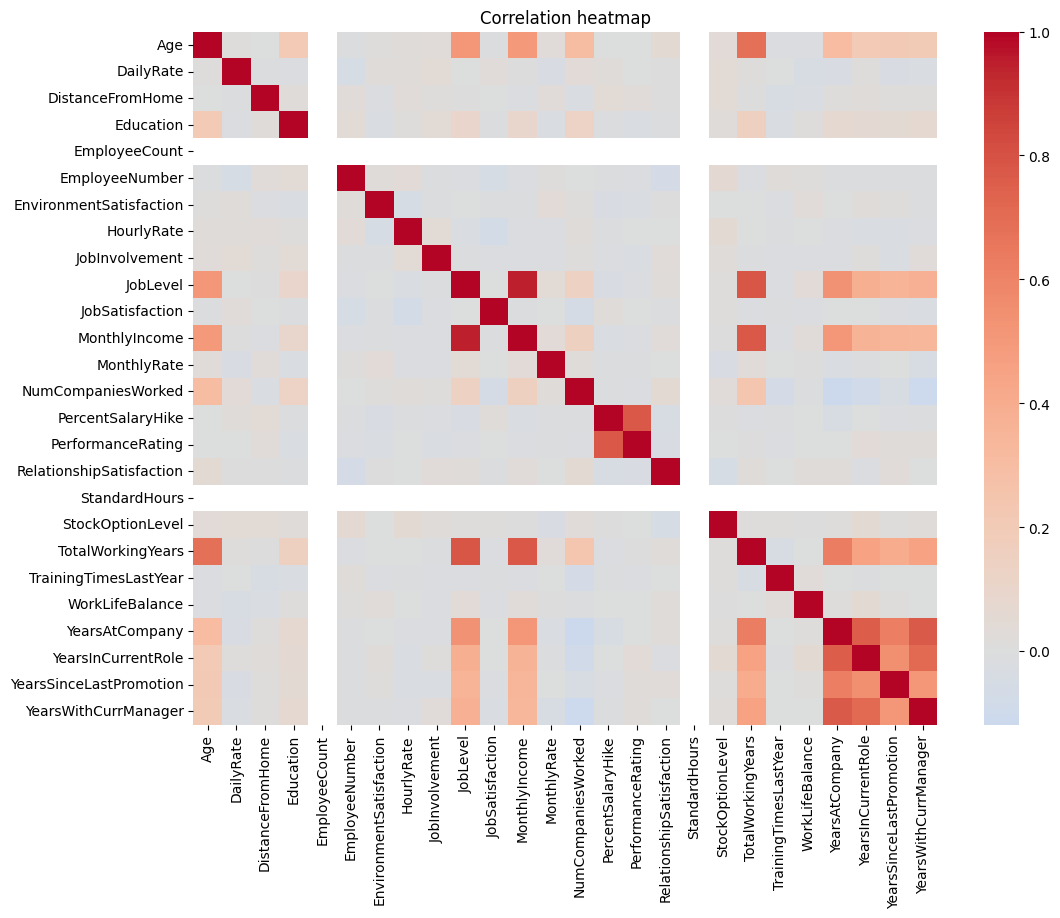

In [5]:
print(df.isnull().sum().sum(), "missing values")
print(df['Attrition'].value_counts(normalize=True))

sns.countplot(x='Attrition', data=df); plt.title("Class balance"); plt.show()
sns.countplot(x='OverTime', hue='Attrition', data=df); plt.show()
sns.boxplot(x='Attrition', y='MonthlyIncome', data=df); plt.show()

plt.figure(figsize=(12,9))
sns.heatmap(df.select_dtypes('number').corr(), cmap='coolwarm', center=0)
plt.title("Correlation heatmap"); plt.show()

In [6]:
# Drop constant / ID columns
df = df.drop(columns=['EmployeeCount','StandardHours','Over18','EmployeeNumber'])

X = df.drop(columns='Attrition')
y = (df['Attrition'] == 'Yes').astype(int)

cat_cols = X.select_dtypes('object').columns.tolist()
num_cols = X.select_dtypes('number').columns.tolist()

def make_prep():
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

neg, pos = (y_train==0).sum(), (y_train==1).sum()

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight='balanced'),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             scale_pos_weight=neg/pos, eval_metric='logloss', random_state=42),
}

def evaluate(name, pipe, X_te, y_te):
    pred = pipe.predict(X_te)
    proba = pipe.predict_proba(X_te)[:,1]
    return {"Model": name,
            "Accuracy": accuracy_score(y_te, pred),
            "Precision": precision_score(y_te, pred, zero_division=0),
            "Recall": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred),
            "ROC-AUC": roc_auc_score(y_te, proba)}

fitted, results = {}, []
for name, m in models.items():
    pipe = Pipeline([('prep', make_prep()), ('model', m)]).fit(X_train, y_train)
    fitted[name] = pipe
    results.append(evaluate(name, pipe, X_test, y_test))

baseline = pd.DataFrame(results).set_index("Model").round(3)
baseline

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.752,0.349,0.638,0.451,0.803
Decision Tree,0.786,0.379,0.532,0.442,0.653
Random Forest,0.847,0.625,0.106,0.182,0.790
XGBoost,0.840,0.500,0.404,0.447,0.774


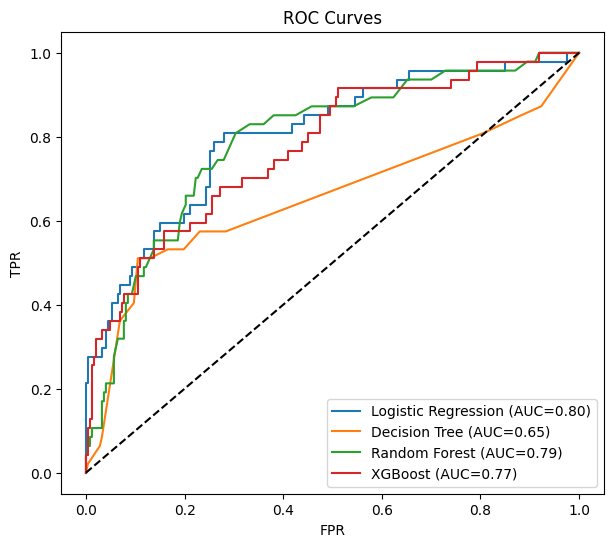

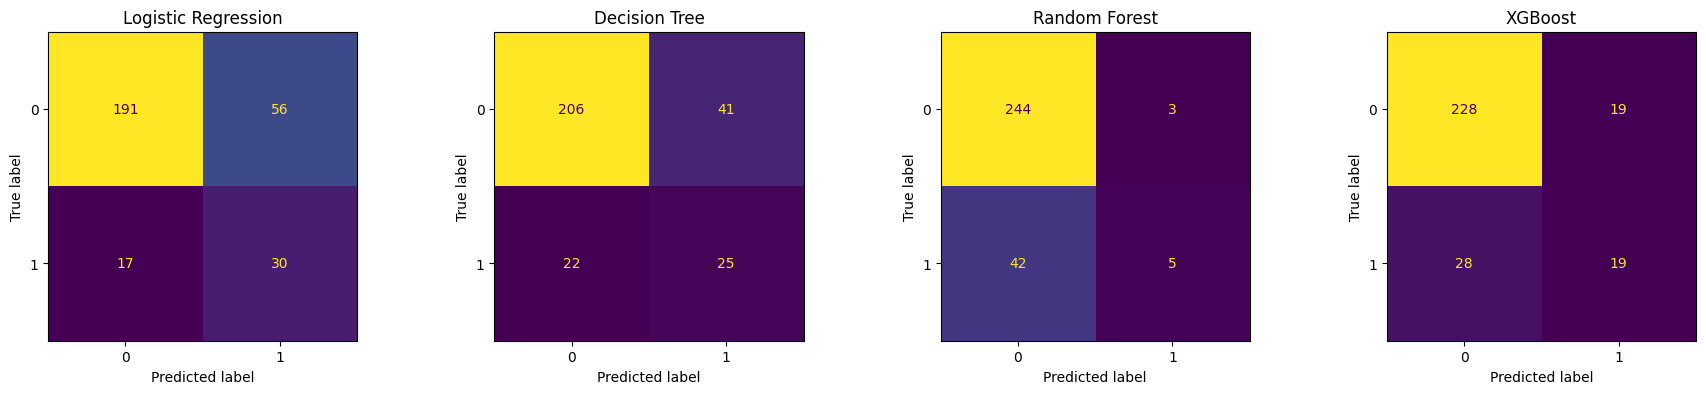

In [8]:
plt.figure(figsize=(7,6))
for name, pipe in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:,1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, pipe.predict_proba(X_test)[:,1]):.2f})")
plt.plot([0,1],[0,1],'k--'); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("ROC Curves"); plt.legend(); plt.show()

fig, axes = plt.subplots(1,4, figsize=(18,4))
for ax,(name,pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, m in models.items():
    pipe = Pipeline([('prep', make_prep()), ('model', m)])
    auc = cross_val_score(pipe, X, y, cv=skf, scoring='roc_auc')
    f1  = cross_val_score(pipe, X, y, cv=skf, scoring='f1')
    cv_rows.append({"Model": name, "CV ROC-AUC mean": auc.mean(), "CV ROC-AUC std": auc.std(),
                    "CV F1 mean": f1.mean(), "CV F1 std": f1.std()})
pd.DataFrame(cv_rows).set_index("Model").round(3)

,CV ROC-AUC mean,CV ROC-AUC std,CV F1 mean,CV F1 std
Model,,,,
Logistic Regression,0.824,0.023,0.482,0.021
Decision Tree,0.692,0.033,0.441,0.032
Random Forest,0.803,0.030,0.246,0.048
XGBoost,0.793,0.010,0.482,0.053


In [10]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100], "model__penalty": ["l2"]},
    "Decision Tree": {"model__max_depth": [3,4,5,6,8,10], "model__min_samples_split": [2,10,20],
                      "model__min_samples_leaf": [1,5,10]},
    "Random Forest": {"model__n_estimators": [200,300,500], "model__max_depth": [None,6,10,15],
                      "model__min_samples_leaf": [1,2,5], "model__max_features": ["sqrt","log2"]},
    "XGBoost": {"model__n_estimators": [200,300,500], "model__max_depth": [3,4,5,6],
                "model__learning_rate": [0.01,0.05,0.1], "model__subsample": [0.7,0.85,1.0],
                "model__colsample_bytree": [0.7,0.85,1.0]},
}

tuned, tuned_results = {}, []
for name, m in models.items():
    pipe = Pipeline([('prep', make_prep()), ('model', m)])
    search = RandomizedSearchCV(pipe, param_grids[name], n_iter=15, scoring='roc_auc',
                                cv=skf, random_state=42, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    print(name, "->", search.best_params_, "CV AUC:", round(search.best_score_,3))
    tuned_results.append(evaluate(name + " (tuned)", search.best_estimator_, X_test, y_test))

tuned_df = pd.DataFrame(tuned_results).set_index("Model").round(3)
pd.concat([baseline, tuned_df])

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 5 is smaller than n_iter=15. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Logistic Regression -> {'model__penalty': 'l2', 'model__C': 0.1} CV AUC: 0.831
Decision Tree -> {'model__min_samples_split': 20, 'model__min_samples_leaf': 10, 'model__max_depth': 4} CV AUC: 0.724
Random Forest -> {'model__n_estimators': 300, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': None} CV AUC: 0.812
XGBoost -> {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.85} CV AUC: 0.825


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.752,0.349,0.638,0.451,0.803
Decision Tree,0.786,0.379,0.532,0.442,0.653
Random Forest,0.847,0.625,0.106,0.182,0.790
XGBoost,0.840,0.500,0.404,0.447,0.774
Logistic Regression (tuned),0.772,0.381,0.681,0.489,0.812
Decision Tree (tuned),0.728,0.301,0.532,0.385,0.704
Random Forest (tuned),0.850,0.714,0.106,0.185,0.801
XGBoost (tuned),0.827,0.466,0.574,0.514,0.788


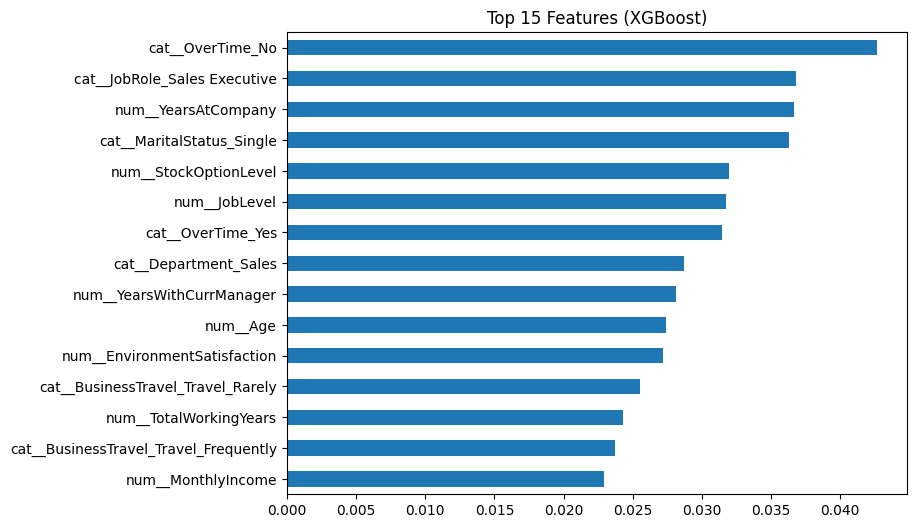

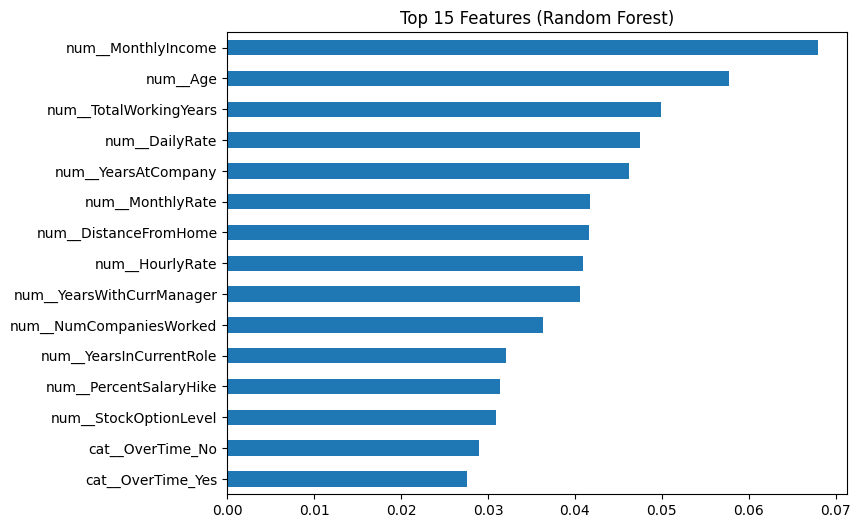

cat__OverTime_No                        -0.689174
cat__BusinessTravel_Non-Travel          -0.589587
num__TotalWorkingYears                  -0.390836
num__EnvironmentSatisfaction            -0.366385
cat__JobRole_Research Director          -0.363127
num__YearsWithCurrManager               -0.362351
cat__EducationField_Other               -0.342163
num__JobSatisfaction                    -0.340037
cat__Department_Sales                    0.313296
cat__MaritalStatus_Single                0.376765
num__NumCompaniesWorked                  0.382479
num__YearsSinceLastPromotion             0.423979
cat__JobRole_Sales Representative        0.441988
cat__BusinessTravel_Travel_Frequently    0.584424
cat__JobRole_Laboratory Technician       0.676529
cat__OverTime_Yes                        0.687511
dtype: float64


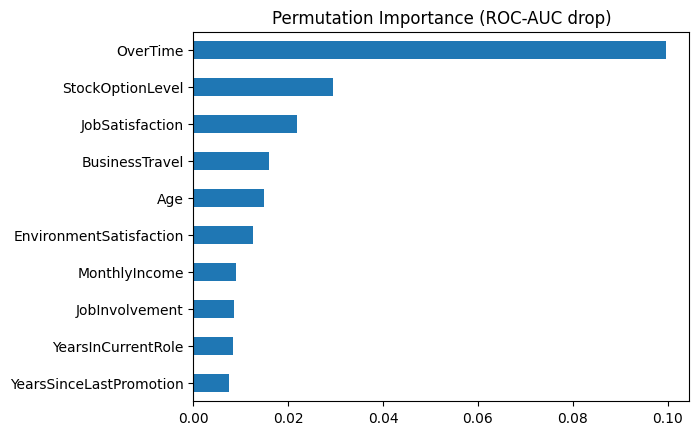

In [11]:
best = tuned["XGBoost"]   # or whichever model has the best AUC above
names = best.named_steps['prep'].get_feature_names_out()

imp = pd.Series(best.named_steps['model'].feature_importances_, index=names).sort_values(ascending=False).head(15)
imp.iloc[::-1].plot(kind='barh', figsize=(8,6), title="Top 15 Features (XGBoost)")
plt.show()

# Random Forest importance
rf = tuned["Random Forest"]
rf_imp = pd.Series(rf.named_steps['model'].feature_importances_,
                   index=rf.named_steps['prep'].get_feature_names_out()).sort_values(ascending=False).head(15)
rf_imp.iloc[::-1].plot(kind='barh', figsize=(8,6), title="Top 15 Features (Random Forest)")
plt.show()

# Logistic Regression coefficients (direction of effect)
lr = tuned["Logistic Regression"]
coef = pd.Series(lr.named_steps['model'].coef_[0],
                 index=lr.named_steps['prep'].get_feature_names_out()).sort_values()
print(pd.concat([coef.head(8), coef.tail(8)]))

# Permutation importance (model-agnostic, on raw features)
pi = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=42)
pd.Series(pi.importances_mean, index=X.columns).sort_values().tail(10).plot(
    kind='barh', title="Permutation Importance (ROC-AUC drop)"); plt.show()

In [12]:
proba = best.predict_proba(X_test)[:,1]
rows = []
for t in [0.2,0.3,0.4,0.5,0.6]:
    p = (proba >= t).astype(int)
    rows.append({"Threshold": t, "Precision": precision_score(y_test,p,zero_division=0),
                 "Recall": recall_score(y_test,p), "F1": f1_score(y_test,p)})
pd.DataFrame(rows).round(3)

,Threshold,Precision,Recall,F1
0,0.2,0.260,0.851,0.398
1,0.3,0.324,0.723,0.447
2,0.4,0.370,0.638,0.469
3,0.5,0.466,0.574,0.514
4,0.6,0.588,0.426,0.494


In [13]:
# PerformanceRating has only 2 values in this dataset, so JobSatisfaction (1-4) is the better target
Xr = df.drop(columns=['JobSatisfaction'])
Xr['Attrition'] = (Xr['Attrition']=='Yes').astype(int)
yr = df['JobSatisfaction']

cat_r = Xr.select_dtypes('object').columns.tolist()
num_r = Xr.select_dtypes('number').columns.tolist()
prep_r = ColumnTransformer([('num', StandardScaler(), num_r),
                            ('cat', OneHotEncoder(handle_unknown='ignore'), cat_r)])

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42)

reg_models = {
    "Random Forest Regressor": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "XGBoost Regressor": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42),
}
reg_rows = []
for name, m in reg_models.items():
    pipe = Pipeline([('prep', prep_r), ('model', m)]).fit(Xr_tr, yr_tr)
    p = pipe.predict(Xr_te)
    cv_r2 = cross_val_score(pipe, Xr, yr, cv=KFold(5, shuffle=True, random_state=42), scoring='r2').mean()
    reg_rows.append({"Model": name, "MAE": mean_absolute_error(yr_te,p),
                     "RMSE": np.sqrt(mean_squared_error(yr_te,p)), "R2": r2_score(yr_te,p), "CV R2": cv_r2})
pd.DataFrame(reg_rows).set_index("Model").round(3)

,MAE,RMSE,R2,CV R2
Model,,,,
Random Forest Regressor,0.955,1.124,0.000,-0.042
XGBoost Regressor,0.984,1.169,-0.082,-0.118
